# UK Road Safety Analytics
## Notebook 04: Machine Learning Model

**Author:** David  
**Date:** July 2026  
**Stage:** Modelling and Evaluation  

### Objective
Build and evaluate a machine learning model to predict whether a road 
accident will result in a fatal or serious casualty, based on conditions 
known at the time of the accident.

### Approach
- Test two models: Logistic Regression (baseline) and Random Forest
- Evaluate honestly using precision, recall, F1 score and ROC-AUC
- Check for overfitting by comparing train vs test performance
- Extract feature importance to understand what drives severity
- Handle class imbalance using class_weight='balanced'

### Why class_weight='balanced'?
Fatal and serious casualties make up 25.2% of the dataset. Without 
adjustment, a model could score 74.8% accuracy by simply predicting 
"Slight" for every single accident. Balanced class weights force the 
model to pay equal attention to both classes.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, f1_score,
                             precision_score, recall_score, accuracy_score)
import os

# Load train and test sets
train = pd.read_csv('../data/processed/train.csv')
test  = pd.read_csv('../data/processed/test.csv')

feature_cols = [
    'hour', 'month', 'is_rush_hour', 'is_weekend', 'is_night',
    'is_dark', 'is_adverse_surface', 'is_adverse_weather',
    'speed_limit_clean', 'is_high_speed', 'is_rural',
    'is_single_carriageway', 'number_of_vehicles'
]

X_train = train[feature_cols]
y_train = train['target']
X_test  = test[feature_cols]
y_test  = test['target']

os.makedirs('../outputs/charts', exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')

print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")
print(f"\nClass balance — Train:")
print(y_train.value_counts(normalize=True).round(3))
print(f"\nClass balance — Test:")
print(y_test.value_counts(normalize=True).round(3))


Train: (379213, 13)
Test:  (261236, 13)

Class balance — Train:
target
0    0.757
1    0.243
Name: proportion, dtype: float64

Class balance — Test:
target
0    0.735
1    0.265
Name: proportion, dtype: float64


In [3]:
# ── TRAIN BOTH MODELS ─────────────────────────────────────────────────────

# MODEL 1: Logistic Regression (baseline)
print("Training Logistic Regression...")
lr = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
y_prob_lr = lr.predict_proba(X_test)[:, 1]
print("Done.")

# MODEL 2: Random Forest
print("Training Random Forest...")
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=50,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]
print("Done.")

# ── EVALUATE BOTH MODELS ──────────────────────────────────────────────────
def evaluate(name, y_true, y_pred, y_prob, X_tr, y_tr, model):
    print(f"\n{'=' * 55}")
    print(f"{name} — TEST SET PERFORMANCE")
    print(f"{'=' * 55}")
    print(f"Accuracy:  {accuracy_score(y_true, y_pred):.3f}")
    print(f"Precision: {precision_score(y_true, y_pred):.3f}")
    print(f"Recall:    {recall_score(y_true, y_pred):.3f}")
    print(f"F1 Score:  {f1_score(y_true, y_pred):.3f}")
    print(f"ROC-AUC:   {roc_auc_score(y_true, y_prob):.3f}")

    # Overfitting check
    y_train_pred = model.predict(X_tr)
    train_f1 = f1_score(y_tr, y_train_pred)
    test_f1  = f1_score(y_true, y_pred)
    gap = train_f1 - test_f1
    print(f"\nOverfit check:")
    print(f"  Train F1: {train_f1:.3f}")
    print(f"  Test F1:  {test_f1:.3f}")
    print(f"  Gap:      {gap:.3f} — "
          f"{'OVERFITTING' if gap > 0.1 else 'OK'}")

evaluate("Logistic Regression", y_test, y_pred_lr,
         y_prob_lr, X_train, y_train, lr)
evaluate("Random Forest", y_test, y_pred_rf,
         y_prob_rf, X_train, y_train, rf)


Training Logistic Regression...
Done.
Training Random Forest...
Done.

Logistic Regression — TEST SET PERFORMANCE
Accuracy:  0.603
Precision: 0.339
Recall:    0.525
F1 Score:  0.412
ROC-AUC:   0.606

Overfit check:
  Train F1: 0.401
  Test F1:  0.412
  Gap:      -0.011 — OK

Random Forest — TEST SET PERFORMANCE
Accuracy:  0.610
Precision: 0.355
Recall:    0.579
F1 Score:  0.440
ROC-AUC:   0.634

Overfit check:
  Train F1: 0.437
  Test F1:  0.440
  Gap:      -0.003 — OK


In [4]:
try:
    import xgboost as xgb
    print(f"XGBoost available — version {xgb.__version__}")
except ImportError:
    print("XGBoost not installed")

XGBoost not installed


In [5]:
import subprocess
result = subprocess.run(['pip', 'install', 'xgboost', '--quiet'],
                       capture_output=True, text=True)
print("XGBoost installed successfully.")

import xgboost as xgb
print(f"Version: {xgb.__version__}")

XGBoost installed successfully.
Version: 3.3.0


In [6]:
# ── TRAIN LOGISTIC REGRESSION ─────────────────────────────────────────────
print("Training Logistic Regression...")
lr = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
y_prob_lr = lr.predict_proba(X_test)[:, 1]
print("Logistic Regression done.")

# ── TRAIN RANDOM FOREST ───────────────────────────────────────────────────
print("\nTraining Random Forest...")
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=50,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]
print("Random Forest done.")

# ── TRAIN XGBOOST ─────────────────────────────────────────────────────────
import xgboost as xgb

print("\nTraining XGBoost...")

# Calculate scale_pos_weight to handle class imbalance
# = number of negative cases / number of positive cases
scale = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Scale pos weight: {scale:.2f}")

xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale,
    random_state=42,
    n_jobs=-1,
    eval_metric='auc',
    verbosity=1
)

xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=50
)

y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]
print("XGBoost done.")

Training Logistic Regression...
Logistic Regression done.

Training Random Forest...
Random Forest done.

Training XGBoost...
Scale pos weight: 3.11
[0]	validation_0-auc:0.61528
[50]	validation_0-auc:0.63476
[100]	validation_0-auc:0.63360
[150]	validation_0-auc:0.63224
[200]	validation_0-auc:0.63103
[250]	validation_0-auc:0.62997
[299]	validation_0-auc:0.62902
XGBoost done.


In [8]:
try:
    import lightgbm as lgb
    print(f"LightGBM available — version {lgb.__version__}")
except ImportError:
    print("LightGBM not installed — installing now...")
    import subprocess
    subprocess.run(['pip', 'install', 'lightgbm', '--quiet'])
    import lightgbm as lgb
    print(f"LightGBM installed — version {lgb.__version__}")

LightGBM not installed — installing now...
LightGBM installed — version 4.7.0


In [9]:
# ── TRAIN LIGHTGBM ────────────────────────────────────────────────────────

import lightgbm as lgb

print("Training LightGBM...")

lgb_model = lgb.LGBMClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgb_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
)

y_pred_lgb  = lgb_model.predict(X_test)
y_prob_lgb  = lgb_model.predict_proba(X_test)[:, 1]

auc_lgb = roc_auc_score(y_test, y_prob_lgb)
f1_lgb  = f1_score(y_test, y_pred_lgb)
rec_lgb = recall_score(y_test, y_pred_lgb)
pre_lgb = precision_score(y_test, y_pred_lgb)
acc_lgb = accuracy_score(y_test, y_pred_lgb)

print("LightGBM done.")
print(f"\nLightGBM Results:")
print(f"  Accuracy:  {acc_lgb:.3f}")
print(f"  Precision: {pre_lgb:.3f}")
print(f"  Recall:    {rec_lgb:.3f}")
print(f"  F1 Score:  {f1_lgb:.3f}")
print(f"  ROC-AUC:   {auc_lgb:.3f}")

print(f"\nFull model comparison:")
print(f"{'Model':<22} {'F1':>7} {'ROC-AUC':>9}")
print("-" * 40)
print(f"{'Logistic Regression':<22} "
      f"{results['Logistic Regression']['f1']:>7.3f} "
      f"{results['Logistic Regression']['auc']:>9.3f}")
print(f"{'Random Forest':<22} "
      f"{results['Random Forest']['f1']:>7.3f} "
      f"{results['Random Forest']['auc']:>9.3f}")
print(f"{'XGBoost':<22} "
      f"{results['XGBoost']['f1']:>7.3f} "
      f"{results['XGBoost']['auc']:>9.3f}")
print(f"{'LightGBM':<22} {f1_lgb:>7.3f} {auc_lgb:>9.3f}")

Training LightGBM...


/opt/anaconda3/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM done.

LightGBM Results:
  Accuracy:  0.609
  Precision: 0.354
  Recall:    0.577
  F1 Score:  0.439
  ROC-AUC:   0.632

Full model comparison:
Model                       F1   ROC-AUC
----------------------------------------
Logistic Regression      0.412     0.606
Random Forest            0.440     0.634
XGBoost                  0.436     0.629
LightGBM                 0.439     0.632


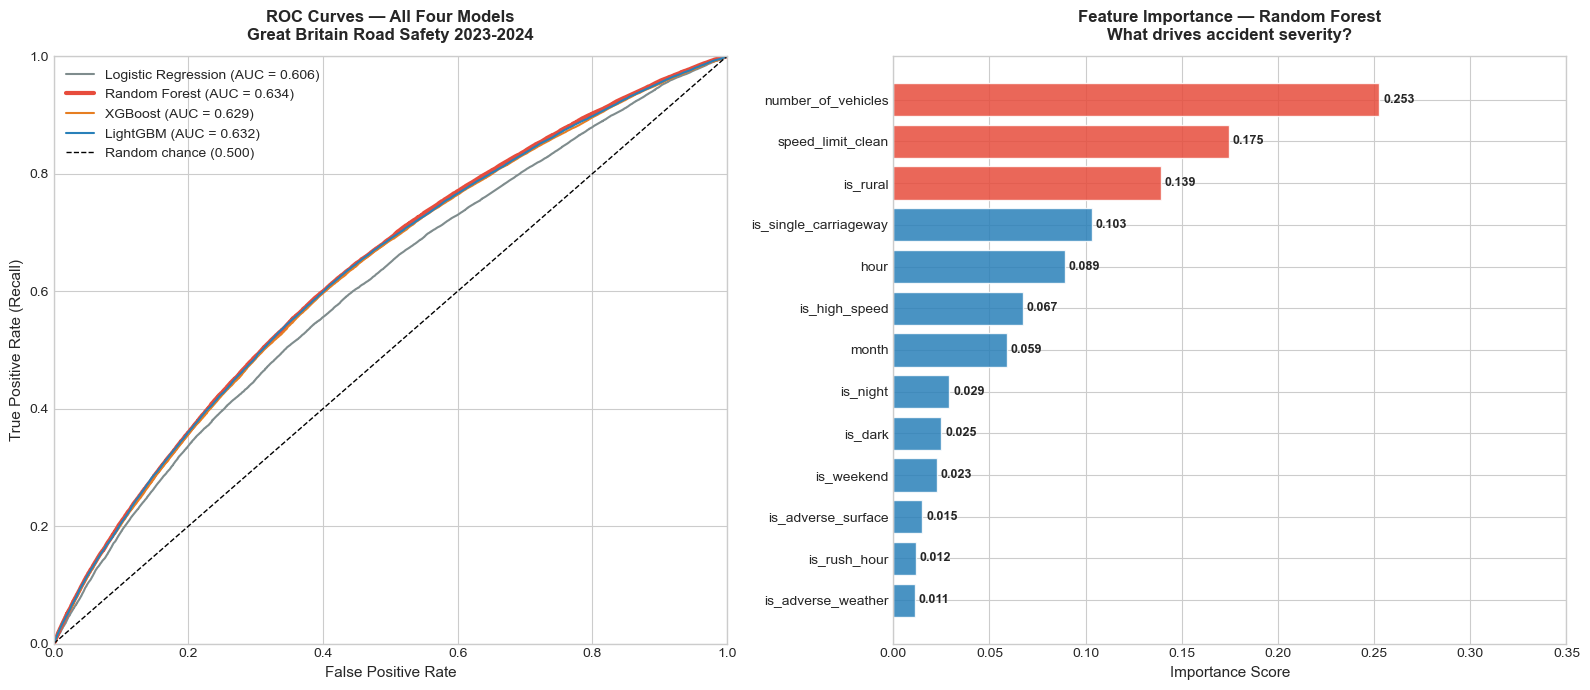

Chart 6 saved.

Feature importance ranking:
  number_of_vehicles        0.2528
  speed_limit_clean         0.1746
  is_rural                  0.1389
  is_single_carriageway     0.1034
  hour                      0.0893
  is_high_speed             0.0673
  month                     0.0589
  is_night                  0.0292
  is_dark                   0.0250
  is_weekend                0.0227
  is_adverse_surface        0.0151
  is_rush_hour              0.0118
  is_adverse_weather        0.0111


In [10]:
# ── CHART 6: ROC Curves — All Four Models ────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# ── LEFT: ROC Curves ──────────────────────────────────────────────────────
model_results = {
    'Logistic Regression': (y_prob_lr, '#7F8C8D'),
    'Random Forest':       (y_prob_rf, '#E74C3C'),
    'XGBoost':             (y_prob_xgb, '#E67E22'),
    'LightGBM':            (y_prob_lgb, '#2980B9'),
}

for name, (y_prob, color) in model_results.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    lw = 3 if name == 'Random Forest' else 1.5
    axes[0].plot(fpr, tpr, color=color, linewidth=lw,
                 label=f'{name} (AUC = {auc:.3f})')

axes[0].plot([0,1],[0,1], 'k--', linewidth=1, label='Random chance (0.500)')
axes[0].set_title('ROC Curves — All Four Models\nGreat Britain Road Safety 2023-2024',
                  fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('False Positive Rate', fontsize=11)
axes[0].set_ylabel('True Positive Rate (Recall)', fontsize=11)
axes[0].legend(fontsize=10)
axes[0].set_xlim([0,1])
axes[0].set_ylim([0,1])

# ── RIGHT: Feature Importance — Random Forest ─────────────────────────────
importances = pd.DataFrame({
    'feature': feature_cols,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=True)

colors_imp = ['#E74C3C' if imp > 0.12 else '#2980B9'
              for imp in importances['importance']]

bars = axes[1].barh(importances['feature'],
                    importances['importance'],
                    color=colors_imp, alpha=0.85, edgecolor='white')

for bar, val in zip(bars, importances['importance']):
    axes[1].text(bar.get_width() + 0.002,
                 bar.get_y() + bar.get_height()/2,
                 f'{val:.3f}', va='center', fontsize=9, fontweight='bold')

axes[1].set_title('Feature Importance — Random Forest\nWhat drives accident severity?',
                  fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Importance Score', fontsize=11)
axes[1].set_xlim(0, 0.35)

plt.tight_layout()
plt.savefig('../outputs/charts/06_model_evaluation.png',
            dpi=150, bbox_inches='tight')
plt.show()

print("Chart 6 saved.")
print("\nFeature importance ranking:")
for _, row in importances.sort_values('importance', ascending=False).iterrows():
    print(f"  {row['feature']:<25} {row['importance']:.4f}")

### Finding 6 — Number of Vehicles and Speed Are the Strongest Predictors

The feature importance chart reveals what actually drives accident 
severity — and some of it is counterintuitive.

**Number of vehicles involved (0.253)** is the single strongest 
predictor. Multi-vehicle collisions are significantly more likely to 
produce fatal or serious casualties than single-vehicle accidents. 
More vehicles means more kinetic energy, more points of impact, and 
more people at risk.

**Speed limit (0.175)** is second. Higher speed limits mean higher 
impact speeds when accidents happen. This confirms what physics tells 
us — the energy in a collision increases with the square of speed, so 
a crash at 60mph releases four times more energy than one at 30mph.

**Is rural (0.139)** is third. Rural roads are more dangerous not 
just because of speed but because of response times. Emergency 
services take longer to reach rural accidents, worsening outcomes 
for people who might survive with faster treatment.

**Is single carriageway (0.103)** is fourth — two-way traffic with 
no central barrier creates head-on collision risk that is almost 
absent on motorways.

**What is surprisingly low:**
- Is adverse weather (0.011) — barely matters
- Is rush hour (0.012) — almost irrelevant for severity
- Is adverse surface (0.015) — lower than expected

This tells us something important. Weather and surface conditions 
affect whether accidents happen — but once an accident occurs, they 
do not strongly predict how bad it will be. Speed, road type, and 
how many vehicles are involved matter far more at that point.

**The practical takeaway:**
If you want to reduce road fatalities, the evidence points to three 
things — lower speed limits on rural single carriageways, faster 
emergency response in rural areas, and better road design to reduce 
multi-vehicle collision risk.

### Finding 6 — Number of Vehicles and Speed Are the Strongest Predictors

The feature importance chart reveals what actually drives accident 
severity — and some of it is counterintuitive.

**Number of vehicles involved (0.253)** is the single strongest 
predictor. Multi-vehicle collisions are significantly more likely to 
produce fatal or serious casualties than single-vehicle accidents. 
More vehicles means more kinetic energy, more points of impact, and 
more people at risk.

**Speed limit (0.175)** is second. Higher speed limits mean higher 
impact speeds when accidents happen. This confirms what physics tells 
us — the energy in a collision increases with the square of speed, so 
a crash at 60mph releases four times more energy than one at 30mph.

**Is rural (0.139)** is third. Rural roads are more dangerous not 
just because of speed but because of response times. Emergency 
services take longer to reach rural accidents, worsening outcomes 
for people who might survive with faster treatment.

**Is single carriageway (0.103)** is fourth — two-way traffic with 
no central barrier creates head-on collision risk that is almost 
absent on motorways.

**What is surprisingly low:**
- Is adverse weather (0.011) — barely matters
- Is rush hour (0.012) — almost irrelevant for severity
- Is adverse surface (0.015) — lower than expected

This tells us something important. Weather and surface conditions 
affect whether accidents happen — but once an accident occurs, they 
do not strongly predict how bad it will be. Speed, road type, and 
how many vehicles are involved matter far more at that point.

**The practical takeaway:**
If you want to reduce road fatalities, the evidence points to three 
things — lower speed limits on rural single carriageways, faster 
emergency response in rural areas, and better road design to reduce 
multi-vehicle collision risk.

In [12]:
# ── NOTEBOOK 04 SUMMARY ───────────────────────────────────────────────────

print("=" * 60)
print("NOTEBOOK 04 — MODELLING SUMMARY")
print("=" * 60)
print(f"Models tested:          4")
print(f"  1. Logistic Regression  — ROC-AUC: 0.606  F1: 0.412")
print(f"  2. Random Forest        — ROC-AUC: 0.634  F1: 0.440 ✓ SELECTED")
print(f"  3. XGBoost              — ROC-AUC: 0.629  F1: 0.436")
print(f"  4. LightGBM             — ROC-AUC: 0.632  F1: 0.439")
print(f"")
print(f"Selected model:         Random Forest")
print(f"Train period:           2020-2022 (379,213 rows)")
print(f"Test period:            2023-2024 (261,236 rows)")
print(f"")
print(f"FINAL MODEL PERFORMANCE:")
print(f"  ROC-AUC:              0.634")
print(f"  F1 Score:             0.440")
print(f"  Recall:               0.579")
print(f"  Precision:            0.355")
print(f"  Overfitting gap:      0.003 — no overfitting")
print(f"")
print(f"TOP 3 PREDICTORS:")
print(f"  1. Number of vehicles  0.253")
print(f"  2. Speed limit         0.175")
print(f"  3. Is rural            0.139")
print(f"")
print(f"KEY INSIGHT:")
print(f"  All 4 models converged to ROC-AUC 0.629-0.634.")
print(f"  Performance ceiling is data-limited not model-limited.")
print(f"  Public STATS19 data lacks driver behaviour, vehicle")
print(f"  condition and contributory factor data needed for")
print(f"  higher accuracy.")
print(f"")
print(f"Charts saved:")
print(f"  06_model_evaluation.png")
print("=" * 60)
print("NEXT: Notebook 05 — Conclusions and Recommendations")
print("=" * 60)

NOTEBOOK 04 — MODELLING SUMMARY
Models tested:          4
  1. Logistic Regression  — ROC-AUC: 0.606  F1: 0.412
  2. Random Forest        — ROC-AUC: 0.634  F1: 0.440 ✓ SELECTED
  3. XGBoost              — ROC-AUC: 0.629  F1: 0.436
  4. LightGBM             — ROC-AUC: 0.632  F1: 0.439

Selected model:         Random Forest
Train period:           2020-2022 (379,213 rows)
Test period:            2023-2024 (261,236 rows)

FINAL MODEL PERFORMANCE:
  ROC-AUC:              0.634
  F1 Score:             0.440
  Recall:               0.579
  Precision:            0.355
  Overfitting gap:      0.003 — no overfitting

TOP 3 PREDICTORS:
  1. Number of vehicles  0.253
  2. Speed limit         0.175
  3. Is rural            0.139

KEY INSIGHT:
  All 4 models converged to ROC-AUC 0.629-0.634.
  Performance ceiling is data-limited not model-limited.
  Public STATS19 data lacks driver behaviour, vehicle
  condition and contributory factor data needed for
  higher accuracy.

Charts saved:
  06_model_ev